# Harris-Laplace: từ |LoG| trên hình vuông tới ảnh thực tế

Notebook **thí nghiệm**. Mọi cell chỉ *gọi* hàm trong `Hao_Harris_A1.py` (`import Hao_Harris_A1 as h`), không cài đặt lại thuật toán.

- Mục 1–4: ảnh tổng hợp (hình vuông) để thấy σ đỉnh của |LoG| đi theo kích thước vật.
- Mục 5–7: phóng, xoay, và soi từng điểm trên ảnh thật.
- Mục 8: lặp lại phép đo trên nhiều loại ảnh thật có sẵn trong thư mục, rồi quét ξ và log_thresh.

**Chính sách AI:** cell code nào do AI viết đều có dòng *Khai báo AI* kèm prompt ở cell markdown ngay phía trên. Các ghi chú không có dòng đó là của mình. Phần kết luận (mục 9) do AI viết.

## 0. Chuẩn bị

`make_square` tạo hình vuông trắng trên nền đen. `log_at_center` đo |LoG| tại tâm ảnh ở từng σ.

> **Khai báo AI** — cell code ngay dưới do AI (Claude) viết. Prompt (chép từ khai báo trong `Hieu_Harris_Laplace.ipynb`, bạn kiểm tra lại): *"cái nãy h tui với bạn hiểu bản chất bạn có thể viết ra cái notebook đc ko"*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import Hao_Harris_A1 as h


N, C = 256, 128                                   

COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
def make_square(side):
    img = np.zeros((N, N))
    img[C - side // 2:C + side // 2, C - side // 2:C + side // 2] = 255
    return img


def log_at_center(img, sigmas):
    return np.array([h.log_normalized(img, s)[C, C] for s in sigmas])


Tương ứng với một ảnh có nhiều layer đc xắp xếp theo $\sigma$ tăng dần thi tồn tại một điểm là $|LoG|$ Cực đại

## 1. Mỗi tầng của tháp là một σ

Hình vuông 20 px nhìn qua 6 tầng. Vòng đỏ có bán kính σ√2; ô viền đỏ là tầng |LoG| tại tâm lớn nhất.

> **Khai báo AI** — cell code ngay dưới do AI (Claude) viết. Prompt (chép từ khai báo trong `Hieu_Harris_Laplace.ipynb`, bạn kiểm tra lại): *"cái nãy h tui với bạn hiểu bản chất bạn có thể viết ra cái notebook đc ko"*

Tháp σ: [ 1.2  1.4  1.7  2.1  2.5  3.   3.6  4.3  5.2  6.2  7.4  8.9 10.7 12.8
 15.4 18.5 22.2 26.6 31.9]


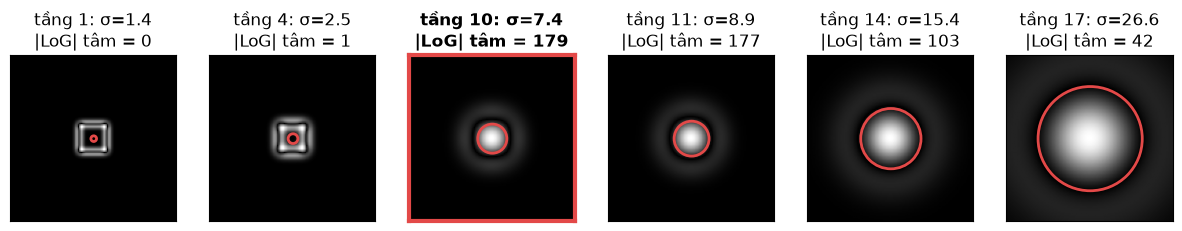

In [2]:
SIGMAS = h.scale_pyramid(sigma0=1.2, xi=1.2, n_levels=18)
print('Tháp σ:', np.round(SIGMAS, 1))

demo = make_square(20)
demo_vals = log_at_center(demo, SIGMAS)
best = int(np.argmax(demo_vals))

fig, axes = plt.subplots(1, 6, figsize=(15, 3.2))
for ax, n in zip(axes, [1, 4, best, 11, 14, 17]):
    ax.imshow(h.log_normalized(demo, SIGMAS[n])[C - 60:C + 60, C - 60:C + 60], cmap='gray')
    ax.add_patch(plt.Circle((60, 60), SIGMAS[n] * np.sqrt(2), fill=False, color='#e34948', lw=2))
    ax.set_title(f'tầng {n}: σ={SIGMAS[n]:.1f}\n|LoG| tâm = {demo_vals[n]:.0f}',
                 fontweight='bold' if n == best else 'normal')
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    if n == best:
        for s in ax.spines.values():
            s.set_visible(True); s.set_color('#e34948'); s.set_linewidth(3)
plt.show()

- Theo bạn có thể thấy nếu vật càng to thì giá trị của $\sigma$ để cho $LoG$ cực đại tương ứng thì có giá trị lớn hơn

## 2. Mỗi vật có một đỉnh theo σ

Đi dọc trục σ tại tâm vật, với 4 kích thước. Đây là bước 2 của `harris_laplace`: giữ điểm ở tầng mà |LoG| lớn hơn hai tầng kề.

> **Khai báo AI** — cell code ngay dưới do AI (Claude) viết. Prompt (chép từ khai báo trong `Hieu_Harris_Laplace.ipynb`, bạn kiểm tra lại): *"cái nãy h tui với bạn hiểu bản chất bạn có thể viết ra cái notebook đc ko"*

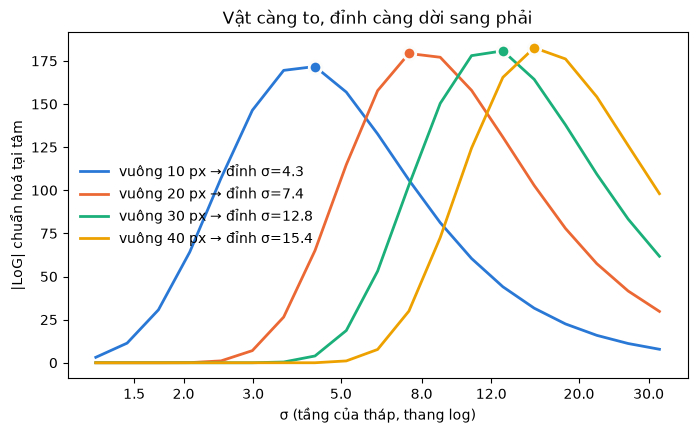

In [3]:
SIZES = [10, 20, 30, 40]
best_sigma = []

fig, ax = plt.subplots(figsize=(8, 4.5))
for side, color in zip(SIZES, COLORS):
    vals = log_at_center(make_square(side), SIGMAS)
    b = int(np.argmax(vals))
    best_sigma.append(SIGMAS[b])
    ax.plot(SIGMAS, vals, color=color, lw=2, label=f'vuông {side} px → đỉnh σ={SIGMAS[b]:.1f}')
    ax.plot(SIGMAS[b], vals[b], 'o', ms=9, color=color, mec='#fcfcfb', mew=2)
ax.set_xscale('log'); ax.set_xticks([1.5, 2, 3, 5, 8, 12, 20, 30])
ax.xaxis.set_major_formatter(plt.ScalarFormatter()); ax.minorticks_off()
ax.set_xlabel('σ (tầng của tháp, thang log)'); ax.set_ylabel('|LoG| chuẩn hoá tại tâm')
ax.set_title('Vật càng to, đỉnh càng dời sang phải'); ax.legend(frameon=False)
plt.show()

## 3. Kích thước vật và σ đỉnh

Chấm (kích thước, σ đỉnh) và khớp đường thẳng qua gốc σ = a · kích thước.

> **Khai báo AI** — cell code ngay dưới do AI (Claude) viết. Prompt (chép từ khai báo trong `Hieu_Harris_Laplace.ipynb`, bạn kiểm tra lại): *"cái nãy h tui với bạn hiểu bản chất bạn có thể viết ra cái notebook đc ko"*

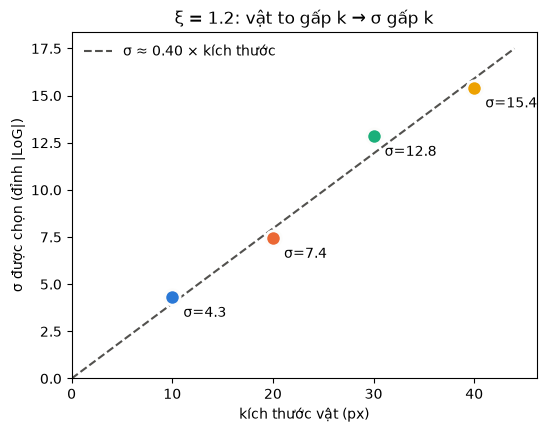

np.float64(0.3976854153619044)

In [4]:
def plot_size_vs_sigma(sizes, best_sigma, title):
    """Chấm (kích thước, σ đỉnh) và đường thẳng qua gốc σ = a·kích thước (bình phương tối thiểu)."""
    sizes, best_sigma = np.array(sizes), np.array(best_sigma)
    a = np.sum(sizes * best_sigma) / np.sum(sizes ** 2)
    fig, ax = plt.subplots(figsize=(6, 4.5))
    xs = np.linspace(0, sizes.max() * 1.1, 10)
    ax.plot(xs, a * xs, '--', color='#52514e', lw=1.5, label=f'σ ≈ {a:.2f} × kích thước')
    for side, sig, color in zip(sizes, best_sigma, COLORS):
        ax.plot(side, sig, 'o', ms=11, color=color, mec='#fcfcfb', mew=2)
        ax.annotate(f'σ={sig:.1f}', (side, sig), textcoords='offset points', xytext=(8, -14))
    ax.set_xlim(0, None); ax.set_ylim(0, None)
    ax.set_xlabel('kích thước vật (px)'); ax.set_ylabel('σ được chọn (đỉnh |LoG|)')
    ax.set_title(title); ax.legend(frameon=False, loc='upper left')
    plt.show()
    return a

plot_size_vs_sigma(SIZES, best_sigma, 'ξ = 1.2: vật to gấp k → σ gấp k')


## 4. Tháp dày hay thưa: ξ

σ chỉ được chọn trong các tầng có sẵn. So ξ = 1.2 với ξ = 2.0 trên cùng dải σ.

> **Khai báo AI** — cell code ngay dưới do AI (Claude) viết. Prompt (chép từ khai báo trong `Hieu_Harris_Laplace.ipynb`, bạn kiểm tra lại): *"cái nãy h tui với bạn hiểu bản chất bạn có thể viết ra cái notebook đc ko"*

ξ=1.2: 19 tầng, σ đỉnh = [ 4.3  7.4 12.8 15.4]


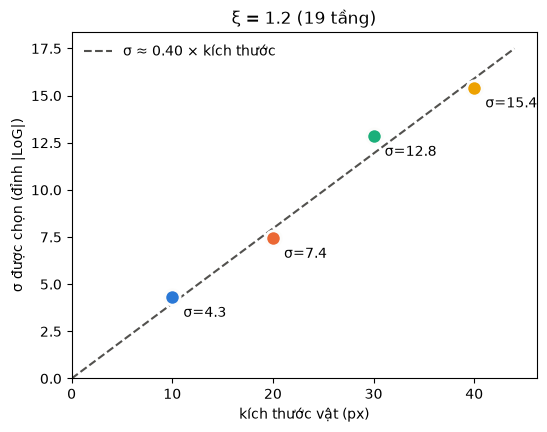

ξ=2.0: 6 tầng, σ đỉnh = [ 4.8  9.6  9.6 19.2]


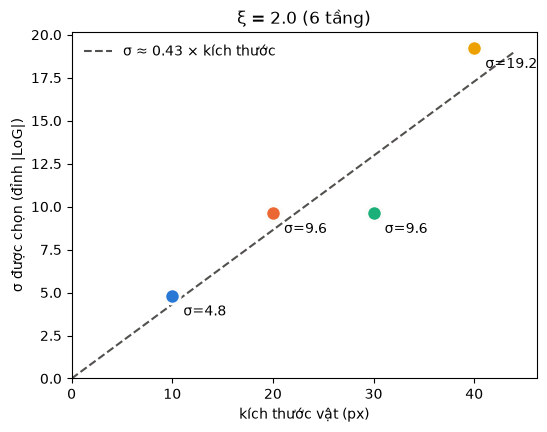

In [5]:
for xi in [1.2, 2.0]:
    n_levels = int(np.ceil(np.log(30 / 1.2) / np.log(xi)))      # luôn phủ σ từ 1.2 tới ~30
    sig = h.scale_pyramid(1.2, xi, n_levels)
    bs = [sig[int(np.argmax(log_at_center(make_square(s), sig)))] for s in SIZES]
    print(f'ξ={xi}: {len(sig)} tầng, σ đỉnh = {np.round(bs, 1)}')
    plot_size_vs_sigma(SIZES, bs, f'ξ = {xi} ({len(sig)} tầng)')

## 5. Phóng ảnh thật

A = ảnh thu về 120 px, B = A phóng `scale` lần. Giữ 100 điểm mạnh nhất của mỗi detector để so công bằng, rồi đo `repeatability`.

> **Khai báo AI** — cell code ngay dưới do AI (Claude) viết. Prompt (chép từ khai báo trong `Hieu_Harris_Laplace.ipynb`, bạn kiểm tra lại): *"cái nãy h tui với bạn hiểu bản chất bạn có thể viết ra cái notebook đc ko"*

In [6]:
SIZE_A, N_KEEP, XI = 120, 100, 1.4
SCALES = [1.0, 1.5, 2.0, 2.5, 3.0]
# dải ×8 trong A, nhân thêm hệ số phóng lớn nhất; +1 vì tầng cuối bị bỏ (thiếu hàng xóm)
SIGMAS_HL = h.scale_pyramid(1.2, XI, int(np.ceil(np.log(8 * max(SCALES)) / np.log(XI))) + 1)


def top_n_by_response(points, n):
    """Giữ n điểm có response (cột cuối) lớn nhất."""
    return points[np.argsort(-points[:, -1])][:n]


def repeat_after_scaling(grey, scale):
    """Repeatability (classic, Harris-Laplace) khi ảnh bị phóng `scale` lần."""
    a = cv.resize(grey, (SIZE_A, SIZE_A), interpolation=cv.INTER_AREA)
    b = cv.resize(a, None, fx=scale, fy=scale, interpolation=cv.INTER_CUBIC)
    t = 0.5 * (scale - 1)                                        # cv.resize căn theo tâm pixel
    S = np.array([[scale, 0, t], [0, scale, t]])                 # A (x, y) -> B (x, y)
    rep_classic = h.repeatability(top_n_by_response(h.harris_classic(a), N_KEEP),
                                  top_n_by_response(h.harris_classic(b), N_KEEP), S, b.shape)
    rep_hl = h.repeatability(top_n_by_response(h.harris_laplace(a, SIGMAS_HL), N_KEEP),
                             top_n_by_response(h.harris_laplace(b, SIGMAS_HL), N_KEEP), S, b.shape)
    return rep_classic, rep_hl


results = {}
for name in ['chess.jpg', 'flowers.jpg']:
    grey = h.convert2grey(cv.imread(name))
    results[name] = np.array([repeat_after_scaling(grey, s) for s in SCALES])
    print(name); print('  scale   classic   Harris-Laplace')
    for s, (rc, rh) in zip(SCALES, results[name]):
        print(f'  {s:4.1f}    {rc:6.3f}    {rh:6.3f}')

chess.jpg
  scale   classic   Harris-Laplace
   1.0     1.000     1.000
   1.5     0.860     0.809
   2.0     0.750     0.872
   2.5     0.520     0.745
   3.0     0.360     0.340


flowers.jpg
  scale   classic   Harris-Laplace
   1.0     1.000     1.000
   1.5     0.541     0.412
   2.0     0.294     0.207
   2.5     0.118     0.126
   3.0     0.094     0.114


Vẽ bảng số ở trên thành đường.

> **Khai báo AI** — cell code ngay dưới do AI (Claude) viết. Prompt (chép từ khai báo trong `Hieu_Harris_Laplace.ipynb`, bạn kiểm tra lại): *"cái nãy h tui với bạn hiểu bản chất bạn có thể viết ra cái notebook đc ko"*

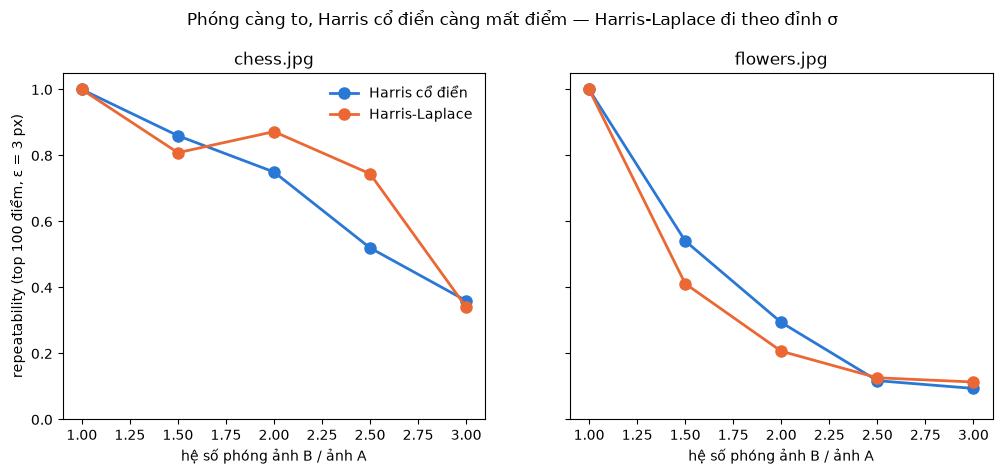

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (name, r) in zip(axes, results.items()):
    ax.plot(SCALES, r[:, 0], 'o-', color=COLORS[0], lw=2, ms=8, label='Harris cổ điển')
    ax.plot(SCALES, r[:, 1], 'o-', color=COLORS[1], lw=2, ms=8, label='Harris-Laplace')
    ax.set_title(name); ax.set_xlabel('hệ số phóng ảnh B / ảnh A'); ax.set_ylim(0, 1.05)
axes[0].set_ylabel(f'repeatability (top {N_KEEP} điểm, ε = 3 px)')
axes[0].legend(frameon=False)
fig.suptitle('Phóng càng to, Harris cổ điển càng mất điểm — Harris-Laplace đi theo đỉnh σ', y=1.02)
plt.show()


## 6. Xoay ảnh

Xoay quanh tâm, bỏ các điểm của B rơi vào góc đen, rồi đo `repeatability` theo góc.

> **Khai báo AI** — cell code ngay dưới do AI (Claude) viết ở phiên trước. **TODO: dán nguyên văn prompt bạn đã dùng vào đây.**

chess.jpg
  góc    classic   Harris-Laplace
    0°     1.000     1.000
   15°     0.930     0.910
   30°     0.927     0.934
   45°     0.926     0.875
   60°     0.927     0.885
   75°     0.980     0.941
   90°     1.000     1.000


flowers.jpg
  góc    classic   Harris-Laplace
    0°     1.000     1.000
   15°     0.979     0.892
   30°     0.966     0.846
   45°     0.977     0.805
   60°     0.988     0.855
   75°     0.989     0.795
   90°     1.000     1.000


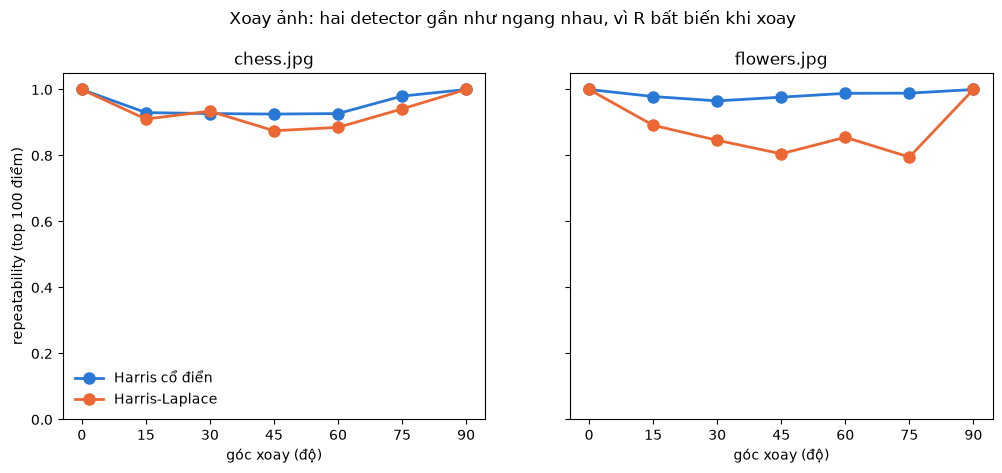

In [8]:
ANGLES = [0, 15, 30, 45, 60, 75, 90]
SIZE_ROT = 240   # lớn hơn SIZE_A để nội suy khi xoay ít làm méo góc


def drop_points_from_black_corners(points, M_inv, shape_a, margin=5):
    """Bỏ điểm q của B nếu T⁻¹(q) = M_inv · [x, y, 1]ᵀ rơi ra ngoài A (vùng đen do xoay)."""
    xy1 = np.column_stack((points[:, 1], points[:, 0], np.ones(len(points))))   # (row, col) -> (x, y, 1)
    x, y = (xy1 @ M_inv.T).T
    H, W = shape_a
    keep = (x >= margin) & (x < W - margin) & (y >= margin) & (y < H - margin)
    return points[keep]


def repeat_after_rotation(grey, angle):
    """Repeatability (classic, Harris-Laplace) khi ảnh bị xoay `angle` độ quanh tâm."""
    a = cv.resize(grey, (SIZE_ROT, SIZE_ROT), interpolation=cv.INTER_AREA)
    center = ((SIZE_ROT - 1) / 2, (SIZE_ROT - 1) / 2)          # tâm pixel thật -> 90° là hoán vị chính xác
    M = cv.getRotationMatrix2D(center, angle, 1.0)             # A (x, y) -> B (x, y)
    b = cv.warpAffine(a, M, (SIZE_ROT, SIZE_ROT), flags=cv.INTER_CUBIC)
    M_inv = cv.invertAffineTransform(M)

    reps = []
    for detect in (h.harris_classic, lambda img: h.harris_laplace(img, SIGMAS_HL)):
        pts_a = top_n_by_response(detect(a), N_KEEP)
        pts_b = top_n_by_response(drop_points_from_black_corners(detect(b), M_inv, a.shape), N_KEEP)
        reps.append(h.repeatability(pts_a, pts_b, M, b.shape))
    return reps


rot_results = {}
for name in ['chess.jpg', 'flowers.jpg']:
    grey = h.convert2grey(cv.imread(name))
    rot_results[name] = np.array([repeat_after_rotation(grey, ang) for ang in ANGLES])
    print(name); print('  góc    classic   Harris-Laplace')
    for ang, (rc, rh) in zip(ANGLES, rot_results[name]):
        print(f'  {ang:3d}°    {rc:6.3f}    {rh:6.3f}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (name, r) in zip(axes, rot_results.items()):
    ax.plot(ANGLES, r[:, 0], 'o-', color=COLORS[0], lw=2, ms=8, label='Harris cổ điển')
    ax.plot(ANGLES, r[:, 1], 'o-', color=COLORS[1], lw=2, ms=8, label='Harris-Laplace')
    ax.set_title(name); ax.set_xlabel('góc xoay (độ)'); ax.set_ylim(0, 1.05); ax.set_xticks(ANGLES)
axes[0].set_ylabel(f'repeatability (top {N_KEEP} điểm)')
axes[0].legend(frameon=False)
fig.suptitle('Xoay ảnh: hai detector gần như ngang nhau, vì R bất biến khi xoay', y=1.02)
plt.show()

## 7. Soi một điểm trước và sau khi zoom

Hàng trên: mọi σ mà Harris tìm thấy điểm đó. Hàng dưới: σ duy nhất mà Harris-Laplace giữ lại. Kỳ vọng σ_B / σ_A ≈ hệ số zoom.

> **Khai báo AI** — cell code ngay dưới do AI (Claude) viết ở phiên trước. **TODO: dán nguyên văn prompt bạn đã dùng vào đây.**

180 điểm ở A, 76 điểm ở B, chọn 1 cặp: [(np.float64(6.19), np.float64(12.84))]


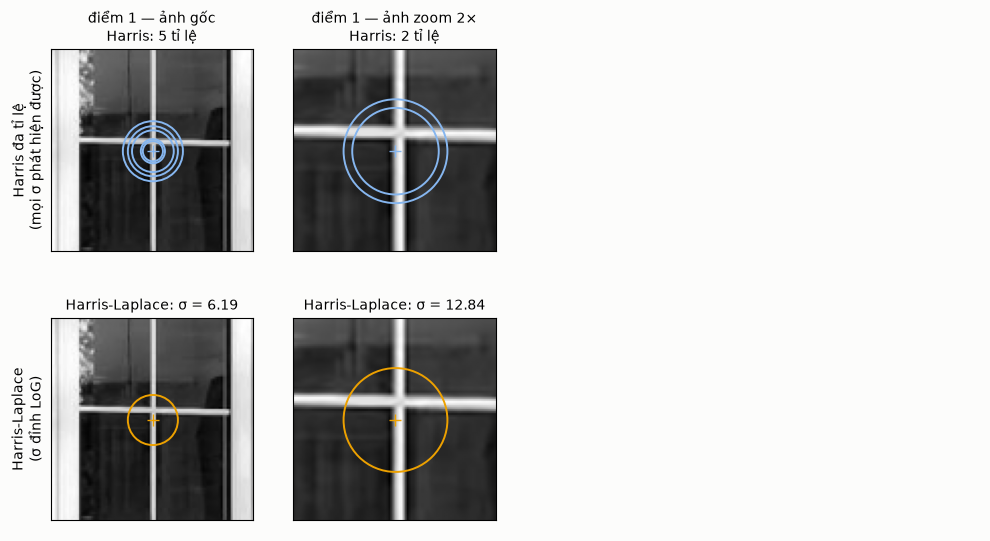

In [9]:
SIZE, ZOOM, CROP =  320, 2.0, 100     # ảnh, cỡ ảnh A, hệ số zoom, cỡ ô cắt
RADIUS_PER_SIGMA = 2.0                                   # bán kính vòng = 2σ (chỉ để hiển thị)
MIN_SIGMA = 3.0
SIGMAS = h.scale_pyramid(1.2, 1.2, 14)
img =  cv.imread('window2.jpg')
grey = h.convert2grey(img)

def zoom_in(img, z):
    n = img.shape[0]
    side = int(round(n / z)); off = (n - side) // 2
    return cv.resize(img[off:off + side, off:off + side], (n, n), interpolation=cv.INTER_CUBIC), off


def harris_scales_at(img, y, x, tol=2):
    """Các σ trong tháp mà Harris (σ_I=σ, σ_D=0.7σ) có cực đại địa phương trong bán kính tol quanh (y, x)."""
    found = []
    for s in SIGMAS:
        R = h.harris_response(img, s, 0.7 * s)
        mask = h.nms_2d(R) & (R > 0.01 * R.max())
        ys, xs = np.nonzero(mask)
        if np.any(np.hypot(ys - y, xs - x) <= tol):
            found.append(s)
    return found


def matched_pairs(pa, pb, off):
    """Cặp điểm Harris-Laplace (A, B) cùng vị trí sau zoom và có σ_B/σ_A gần ZOOM nhất."""
    pairs = []
    for y, x, s, r in pa:
        if s < MIN_SIGMA:
            continue
        yb, xb = ZOOM * (y - off), ZOOM * (x - off)
        inside = CROP // 2 <= min(yb, xb) and max(yb, xb) < SIZE - CROP // 2 and \
                 CROP // 2 <= min(y, x) and max(y, x) < SIZE - CROP // 2
        if not inside:
            continue
        near = pb[np.hypot(pb[:, 0] - yb, pb[:, 1] - xb) <= 3]
        if len(near):
            best = near[np.argmin(np.abs(np.log(near[:, 2] / (ZOOM * s))))]
            pairs.append((abs(np.log(best[2] / s / ZOOM)), -r, (y, x, s), tuple(best[:3])))
    pairs.sort()
    chosen = []
    for _, _, a, b in pairs:                              # giữ các cặp cách nhau >= 20 px để không trùng
        if all(np.hypot(a[0] - c[0], a[1] - c[1]) >= 20 for c, _ in chosen):
            chosen.append((a, b))
    return chosen


def crop(img, y, x):
    """Ô vuông CROP x CROP quanh (y, x)."""
    y, x = int(y), int(x)
    return img[y - CROP // 2:y + CROP // 2, x - CROP // 2:x + CROP // 2]


def draw(ax, img, y, x, scales, color):
    """Vẽ ô cắt quanh (y, x) và một vòng tròn bán kính 2σ cho mỗi σ."""
    ax.imshow(crop(img, y, x), cmap='gray')
    for s in scales:
        ax.add_patch(plt.Circle((CROP // 2, CROP // 2), RADIUS_PER_SIGMA * s, fill=False, color=color, lw=1.4))
    ax.plot(CROP // 2, CROP // 2, '+', color=color, ms=8)
    ax.set_xticks([]); ax.set_yticks([])


A = cv.resize(grey, (SIZE, SIZE), interpolation=cv.INTER_AREA)
B, off = zoom_in(A, ZOOM)
pa, pb = h.harris_laplace(A, SIGMAS), h.harris_laplace(B, SIGMAS)
pairs = matched_pairs(pa, pb, off)[:2]
print(f'{len(pa)} điểm ở A, {len(pb)} điểm ở B, chọn {len(pairs)} cặp:',
      [(round(a[2], 2), round(b[2], 2)) for a, b in pairs])

fig, axes = plt.subplots(2, 4, figsize=(12, 6.4), facecolor='#fcfcfb')
for k, ((ya, xa, sa), (yb, xb, sb)) in enumerate(pairs):
    for col, (img, y, x, s_hl, tag) in enumerate([(A, ya, xa, sa, 'gốc'), (B, yb, xb, sb, f'zoom {ZOOM:g}×')]):
        c = 2 * k + col
        all_s = harris_scales_at(img, y, x)
        draw(axes[0, c], img, y, x, all_s, '#86b6ef')
        draw(axes[1, c], img, y, x, [s_hl], '#eda100')
        axes[0, c].set_title(f'điểm {k + 1} — ảnh {tag}\nHarris: {len(all_s)} tỉ lệ', fontsize=10)
        axes[1, c].set_title(f'Harris-Laplace: σ = {s_hl:.2f}', fontsize=10)
for ax in axes[:, 2 * len(pairs):].ravel():      # ít cặp hơn số cột -> ẩn ô thừa
    ax.axis('off')
axes[0, 0].set_ylabel('Harris đa tỉ lệ\n(mọi σ phát hiện được)')
axes[1, 0].set_ylabel('Harris-Laplace\n(σ đỉnh LoG)')
plt.show()



## 8. Nhiều trường hợp ảnh thực tế

Hai ảnh ở trên chưa đủ để nói chung. Mục này chạy lại đúng các phép đo đó trên 8 ảnh có sẵn, thuộc nhiều loại: góc rõ (bàn cờ, hình vẽ), kiến trúc (cửa sổ, toà nhà), tự nhiên (hoa lá, người), ít chi tiết (trời và đường).

### 8.1 Nhìn bằng mắt trước

Hàng trên là ảnh A, hàng dưới là phần giữa của A phóng to 2×. **Đoán trước khi chạy:** vòng tròn ở hàng dưới sẽ to hơn, nhỏ hơn hay bằng hàng trên?

> **Khai báo AI** — cell code ngay dưới do AI (Claude) viết. Prompt: *"bạn có thẻ viết hoàn chỉnh cái notebook LAP đc ko dựa vào cái file code HA0_harris_1.py đc ko dựa vào phong cách của tui á với lại có thể tương ứng với nhiều trg howp dùng ảnh thực tế có sẵn trong máy của tui đc ko á"*

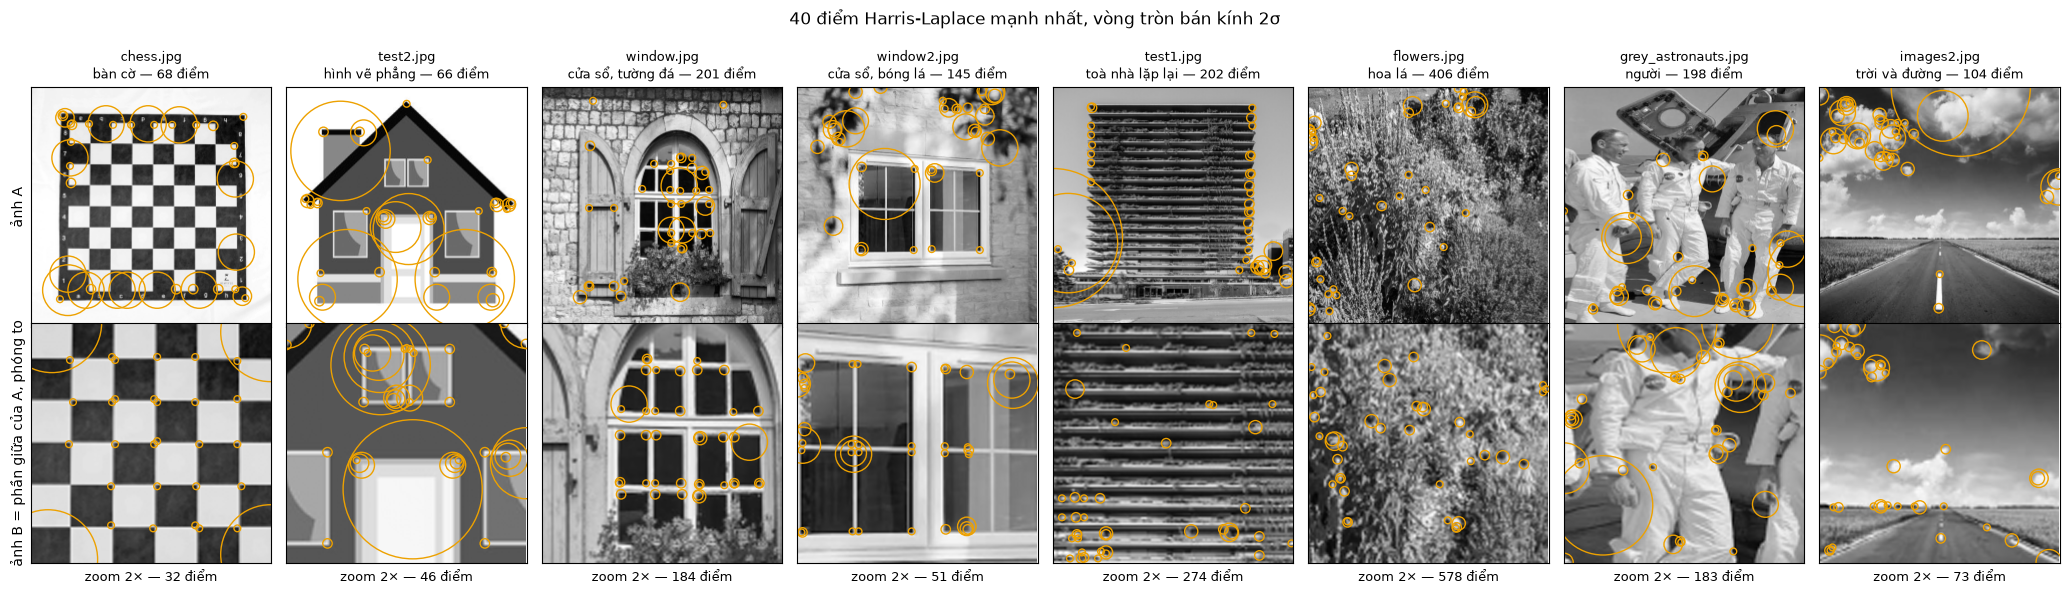

In [10]:
REAL_IMAGES = {                     # file -> loại ảnh. Sửa danh sách này để thử ảnh khác
    'chess.jpg': 'bàn cờ',
    'test2.jpg': 'hình vẽ phẳng',
    'window.jpg': 'cửa sổ, tường đá',
    'window2.jpg': 'cửa sổ, bóng lá',
    'test1.jpg': 'toà nhà lặp lại',
    'flowers.jpg': 'hoa lá',
    'grey_astronauts.jpg': 'người',
    'images2.jpg': 'trời và đường',
}
SIZE_SHOW, ZOOM_SHOW, N_SHOW = 240, 2.0, 40
N_COLS = 4


def load_grey(name):
    """Đọc ảnh rồi đổi sang xám bằng convert2grey; dừng ngay nếu thiếu file."""
    img = cv.imread(name)
    assert img is not None, f'không đọc được {name}'
    return h.convert2grey(img)


def show_scaled_points(ax, img, points):
    """Vẽ ảnh và N_SHOW điểm Harris-Laplace mạnh nhất; mỗi điểm là một vòng tròn bán kính 2σ."""
    ax.imshow(img, cmap='gray')
    for y, x, s, _ in top_n_by_response(points, N_SHOW):
        ax.add_patch(plt.Circle((x, y), RADIUS_PER_SIGMA * s, fill=False, color='#eda100', lw=1))
    ax.set_xlim(0, img.shape[1]); ax.set_ylim(img.shape[0], 0)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)


GREYS = {name: load_grey(name) for name in REAL_IMAGES}

fig, axes = plt.subplots(2, len(GREYS), figsize=(2.6 * len(GREYS), 5.8))
for col, (name, grey) in enumerate(GREYS.items()):
    A = cv.resize(grey, (SIZE_SHOW, SIZE_SHOW), interpolation=cv.INTER_AREA)
    B, _ = zoom_in(A, ZOOM_SHOW)
    pa, pb = h.harris_laplace(A, SIGMAS_HL), h.harris_laplace(B, SIGMAS_HL)
    show_scaled_points(axes[0, col], A, pa)
    show_scaled_points(axes[1, col], B, pb)
    axes[0, col].set_title(f'{name}\n{REAL_IMAGES[name]} — {len(pa)} điểm', fontsize=9)
    axes[1, col].set_xlabel(f'zoom {ZOOM_SHOW:g}× — {len(pb)} điểm', fontsize=9)   # nhãn nằm dưới ảnh để không đè hàng trên
axes[0, 0].set_ylabel('ảnh A'); axes[1, 0].set_ylabel('ảnh B = phần giữa của A, phóng to')
fig.suptitle(f'{N_SHOW} điểm Harris-Laplace mạnh nhất, vòng tròn bán kính 2σ', y=1.0)
plt.tight_layout(); plt.show()


### 8.2 Phóng ảnh

Cùng phép đo ở mục 5 (`repeat_after_scaling`), mỗi ảnh một ô.

> **Khai báo AI** — cell code ngay dưới do AI (Claude) viết. Prompt: *"bạn có thẻ viết hoàn chỉnh cái notebook LAP đc ko dựa vào cái file code HA0_harris_1.py đc ko dựa vào phong cách của tui á với lại có thể tương ứng với nhiều trg howp dùng ảnh thực tế có sẵn trong máy của tui đc ko á"*

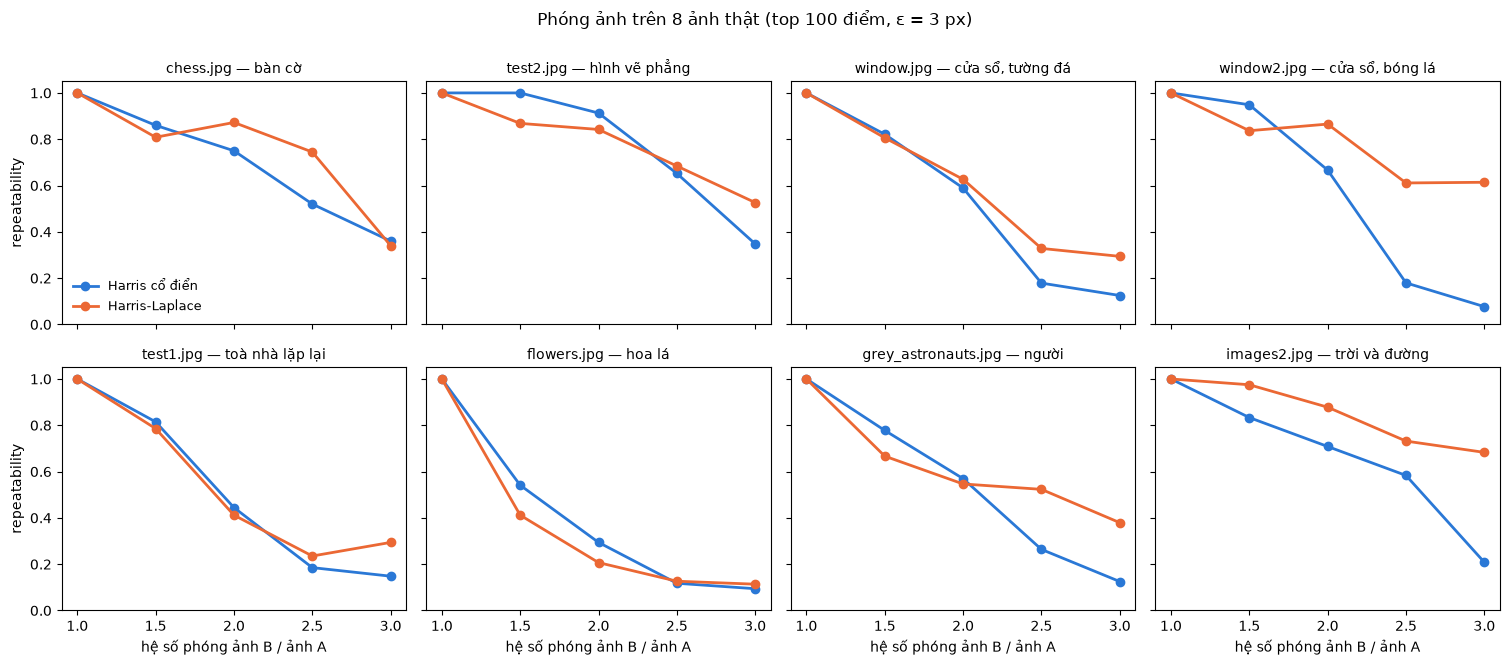

In [11]:
def plot_repeatability_per_image(x, results_by_image, xlabel, title):
    """Mỗi ảnh một ô: repeatability của Harris cổ điển và Harris-Laplace theo x."""
    n_rows = int(np.ceil(len(REAL_IMAGES) / N_COLS))
    fig, axes = plt.subplots(n_rows, N_COLS, figsize=(3.8 * N_COLS, 3.3 * n_rows), sharex=True, sharey=True)
    axes = np.atleast_2d(axes)
    for ax in axes.ravel()[len(REAL_IMAGES):]:
        ax.axis('off')
    for ax, name in zip(axes.ravel(), REAL_IMAGES):
        r = results_by_image[name]
        ax.plot(x, r[:, 0], 'o-', color=COLORS[0], lw=2, ms=6, label='Harris cổ điển')
        ax.plot(x, r[:, 1], 'o-', color=COLORS[1], lw=2, ms=6, label='Harris-Laplace')
        ax.set_title(f'{name} — {REAL_IMAGES[name]}', fontsize=10); ax.set_ylim(0, 1.05)
    for ax in axes[-1]:
        ax.set_xlabel(xlabel)
    for ax in axes[:, 0]:
        ax.set_ylabel('repeatability')
    axes[0, 0].legend(frameon=False, fontsize=9)
    fig.suptitle(title, y=1.0); plt.tight_layout(); plt.show()


for name, grey in GREYS.items():                 # chạy khoảng 2-3 phút vì nms_2d là vòng lặp Python
    if name not in results:                      # chess.jpg, flowers.jpg đã đo ở mục 5
        results[name] = np.array([repeat_after_scaling(grey, s) for s in SCALES])
    # tự kiểm tra: scale = 1 thì B trùng A, nên phải tìm lại được mọi điểm
    assert np.allclose(results[name][0], 1.0), f'{name}: repeatability ở scale 1 phải bằng 1'

plot_repeatability_per_image(SCALES, results, 'hệ số phóng ảnh B / ảnh A',
                             f'Phóng ảnh trên {len(GREYS)} ảnh thật (top {N_KEEP} điểm, ε = 3 px)')


### 8.3 Xoay ảnh

Cùng phép đo ở mục 6 (`repeat_after_rotation`).

> **Khai báo AI** — cell code ngay dưới do AI (Claude) viết. Prompt: *"bạn có thẻ viết hoàn chỉnh cái notebook LAP đc ko dựa vào cái file code HA0_harris_1.py đc ko dựa vào phong cách của tui á với lại có thể tương ứng với nhiều trg howp dùng ảnh thực tế có sẵn trong máy của tui đc ko á"*

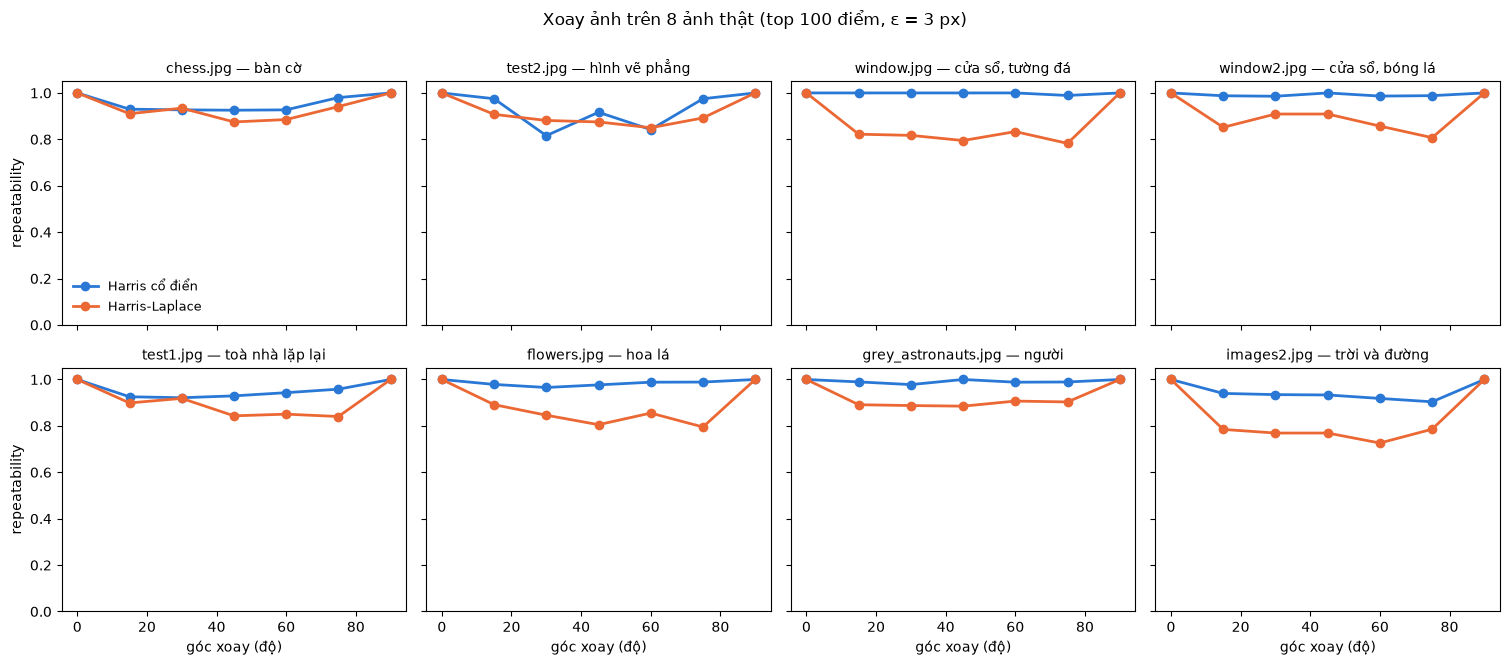

In [12]:
for name, grey in GREYS.items():                 # chạy khoảng 4-5 phút
    if name not in rot_results:                  # chess.jpg, flowers.jpg đã đo ở mục 6
        rot_results[name] = np.array([repeat_after_rotation(grey, ang) for ang in ANGLES])

plot_repeatability_per_image(ANGLES, rot_results, 'góc xoay (độ)',
                             f'Xoay ảnh trên {len(GREYS)} ảnh thật (top {N_KEEP} điểm, ε = 3 px)')


### 8.4 Gom lại một bảng

Mỗi ảnh hai con số ở mức phóng 3×, và trung bình trên các góc xoay.

> **Khai báo AI** — cell code ngay dưới do AI (Claude) viết. Prompt: *"bạn có thẻ viết hoàn chỉnh cái notebook LAP đc ko dựa vào cái file code HA0_harris_1.py đc ko dựa vào phong cách của tui á với lại có thể tương ứng với nhiều trg howp dùng ảnh thực tế có sẵn trong máy của tui đc ko á"*

ảnh                   loại                  phóng 3×: classic    HL   |  xoay (TB): classic    HL
chess.jpg             bàn cờ                            0.36   0.34  |               0.96   0.94
test2.jpg             hình vẽ phẳng                     0.35   0.53  |               0.93   0.92
window.jpg            cửa sổ, tường đá                  0.12   0.29  |               1.00   0.86
window2.jpg           cửa sổ, bóng lá                   0.08   0.61  |               0.99   0.90
test1.jpg             toà nhà lặp lại                   0.15   0.29  |               0.95   0.91
flowers.jpg           hoa lá                            0.09   0.11  |               0.99   0.88
grey_astronauts.jpg   người                             0.12   0.38  |               0.99   0.92
images2.jpg           trời và đường                     0.21   0.68  |               0.95   0.83
TRUNG BÌNH                                              0.19   0.41  |               0.97   0.90


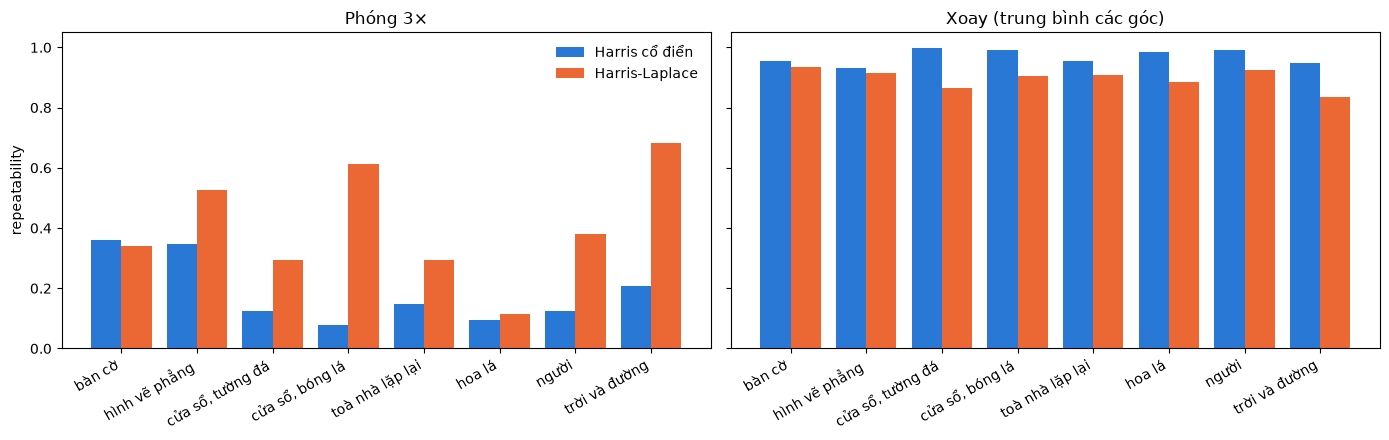

In [13]:
BIG_SCALE = SCALES.index(3.0)                    # đề yêu cầu báo cáo ở mức phóng 3×

names = list(REAL_IMAGES)
scale_rep = np.array([results[n][BIG_SCALE] for n in names])        # (số ảnh, 2): classic, Harris-Laplace
rot_rep = np.array([rot_results[n].mean(axis=0) for n in names])    # trung bình trên mọi góc

print(f'{"ảnh":22s}{"loại":20s}  phóng 3×: classic    HL   |  xoay (TB): classic    HL')
for n, (sc, sh), (rc, rh) in zip(names, scale_rep, rot_rep):
    print(f'{n:22s}{REAL_IMAGES[n]:20s}            {sc:6.2f} {sh:6.2f}  |             {rc:6.2f} {rh:6.2f}')
print(f'{"TRUNG BÌNH":42s}            {scale_rep[:, 0].mean():6.2f} {scale_rep[:, 1].mean():6.2f}  |'
      f'             {rot_rep[:, 0].mean():6.2f} {rot_rep[:, 1].mean():6.2f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
pos = np.arange(len(names))
for ax, rep, title in [(axes[0], scale_rep, 'Phóng 3×'), (axes[1], rot_rep, 'Xoay (trung bình các góc)')]:
    ax.bar(pos - 0.2, rep[:, 0], 0.4, color=COLORS[0], label='Harris cổ điển')
    ax.bar(pos + 0.2, rep[:, 1], 0.4, color=COLORS[1], label='Harris-Laplace')
    ax.set_xticks(pos); ax.set_xticklabels([REAL_IMAGES[n] for n in names], rotation=30, ha='right')
    ax.set_title(title); ax.set_ylim(0, 1.05)
axes[0].set_ylabel('repeatability'); axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()


### 8.5 Quét ξ: tháp dày bao nhiêu là đủ?

Giữ nguyên dải σ, chỉ đổi ξ, nên số tầng thay đổi theo. Đo repeatability khi phóng 2× (trung bình 8 ảnh) và thời gian chạy. **Đoán trước:** ξ càng nhỏ thì repeatability càng cao mãi, hay tới một lúc thì dừng tăng?

> **Khai báo AI** — cell code ngay dưới do AI (Claude) viết. Prompt: *"bạn làm hộ tui đi nói chứ qua môn r bạn ơi nên tui nhờ bạn á bạn bị nhầm á cái này tài liệu của anh chị á"*

ξ=1.10: 40 tầng, repeatability TB = 0.650, 125.6 s


ξ=1.15: 28 tầng, repeatability TB = 0.639,  92.0 s


ξ=1.20: 22 tầng, repeatability TB = 0.664,  69.1 s


ξ=1.30: 16 tầng, repeatability TB = 0.613,  44.7 s


ξ=1.40: 12 tầng, repeatability TB = 0.656,  36.5 s


ξ=1.60:  9 tầng, repeatability TB = 0.603,  24.0 s


ξ=1.80:  8 tầng, repeatability TB = 0.674,  21.4 s


ξ=2.00:  7 tầng, repeatability TB = 0.772,  18.9 s


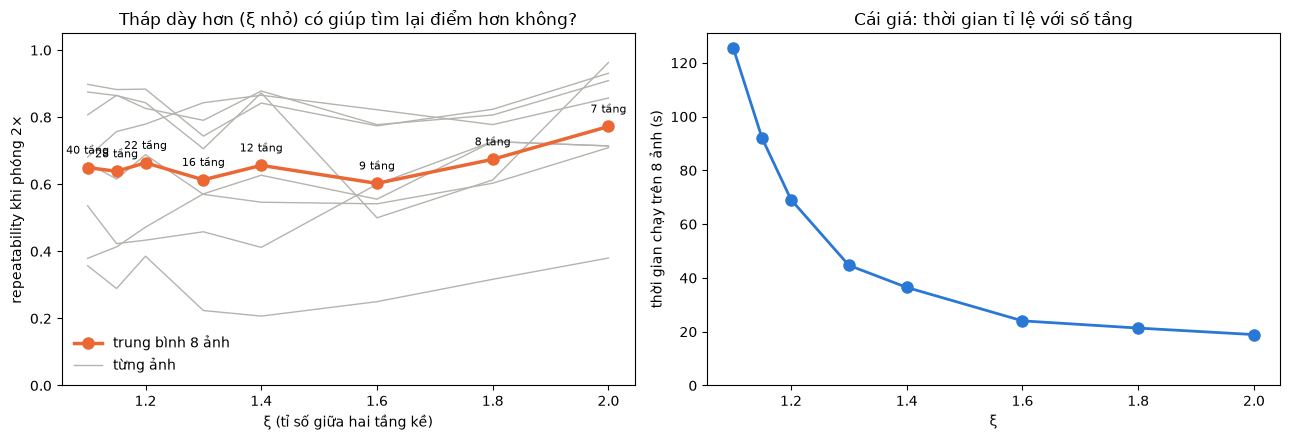

In [14]:
import time

XIS = [1.1, 1.15, 1.2, 1.3, 1.4, 1.6, 1.8, 2.0]
SWEEP_SCALE = 2.0
SIGMA_MAX = SIGMAS_HL[-1]                  # giữ nguyên dải σ như mục 5, chỉ đổi độ dày tầng


def pyramid_covering(xi, sigma_max=SIGMA_MAX, sigma0=1.2):
    """Tháp σ_n = ξ^n · σ0 với số tầng vừa đủ để σ cuối ≥ sigma_max."""
    return h.scale_pyramid(sigma0, xi, int(np.ceil(np.log(sigma_max / sigma0) / np.log(xi))))


def repeat_hl_with_pyramid(grey, scale, sigmas):
    """Repeatability của Harris-Laplace khi ảnh bị phóng `scale` lần, dùng tháp σ cho trước."""
    a = cv.resize(grey, (SIZE_A, SIZE_A), interpolation=cv.INTER_AREA)
    b = cv.resize(a, None, fx=scale, fy=scale, interpolation=cv.INTER_CUBIC)
    t = 0.5 * (scale - 1)
    S = np.array([[scale, 0, t], [0, scale, t]])
    return h.repeatability(top_n_by_response(h.harris_laplace(a, sigmas), N_KEEP),
                           top_n_by_response(h.harris_laplace(b, sigmas), N_KEEP), S, b.shape)


xi_rep = np.zeros((len(REAL_IMAGES), len(XIS)))      # hàng: ảnh, cột: ξ
xi_time = np.zeros(len(XIS))                         # tổng thời gian chạy trên mọi ảnh
n_levels = []
for j, xi in enumerate(XIS):                         # chạy khoảng 5 phút
    sigmas = pyramid_covering(xi)
    n_levels.append(len(sigmas))
    start = time.time()
    for i, grey in enumerate(GREYS.values()):
        xi_rep[i, j] = repeat_hl_with_pyramid(grey, SWEEP_SCALE, sigmas)
    xi_time[j] = time.time() - start
    print(f'ξ={xi:4.2f}: {len(sigmas):2d} tầng, repeatability TB = {xi_rep[:, j].mean():.3f}, {xi_time[j]:5.1f} s')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for row in xi_rep:
    ax1.plot(XIS, row, color='#b5b3ad', lw=1)
ax1.plot(XIS, xi_rep.mean(axis=0), 'o-', color=COLORS[1], lw=2.5, ms=8, label='trung bình 8 ảnh')
ax1.plot([], [], color='#b5b3ad', lw=1, label='từng ảnh')
ax1.set_xlabel('ξ (tỉ số giữa hai tầng kề)'); ax1.set_ylabel(f'repeatability khi phóng {SWEEP_SCALE:g}×')
ax1.set_ylim(0, 1.05); ax1.legend(frameon=False)
ax1.set_title('Tháp dày hơn (ξ nhỏ) có giúp tìm lại điểm hơn không?')
for xi, n, r in zip(XIS, n_levels, xi_rep.mean(axis=0)):
    ax1.annotate(f'{n} tầng', (xi, r), textcoords='offset points', xytext=(0, 10), ha='center', fontsize=8)
ax2.plot(XIS, xi_time, 'o-', color=COLORS[0], lw=2, ms=8)
ax2.set_xlabel('ξ'); ax2.set_ylabel('thời gian chạy trên 8 ảnh (s)'); ax2.set_ylim(0, None)
ax2.set_title('Cái giá: thời gian tỉ lệ với số tầng')
plt.tight_layout(); plt.show()


#### 8.5b Kiểm tra giả thuyết: hệ số phóng trùng số nguyên tầng

Ở 8.5, ξ = 2.0 cao bất thường khi phóng 2×. Giả thuyết: 2× = đúng 1 tầng của ξ = 2. Thử chéo hai hệ số phóng với hai giá trị ξ.

> **Khai báo AI** — cell code ngay dưới do AI (Claude) viết. Prompt: *"bạn làm hộ tui đi nói chứ qua môn r bạn ơi nên tui nhờ bạn á bạn bị nhầm á cái này tài liệu của anh chị á"*

phóng 1.6×: ξ=1.6 (lệch 0.00 tầng) -> 0.812, ξ=2.0 (lệch 0.32 tầng) -> 0.702
phóng 2.0×: ξ=1.6 (lệch 0.47 tầng) -> 0.603, ξ=2.0 (lệch 0.00 tầng) -> 0.772


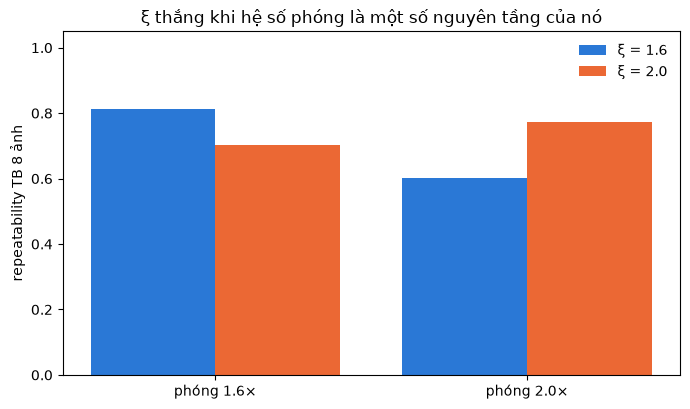

In [15]:
CROSS_ZOOMS, CROSS_XIS = [1.6, 2.0], [1.6, 2.0]


def level_offset(scale, xi):
    """Phóng `scale` lần dời σ đi n = log(scale) / log(ξ) tầng; trả về khoảng cách từ n tới số nguyên gần nhất."""
    n = np.log(scale) / np.log(xi)
    return abs(n - round(n))


cross = np.array([[np.mean([repeat_hl_with_pyramid(g, z, pyramid_covering(xi)) for g in GREYS.values()])
                   for xi in CROSS_XIS] for z in CROSS_ZOOMS])          # chạy khoảng 2 phút
for z, row in zip(CROSS_ZOOMS, cross):
    print(f'phóng {z}×: ' + ', '.join(f'ξ={xi} (lệch {level_offset(z, xi):.2f} tầng) -> {r:.3f}'
                                      for xi, r in zip(CROSS_XIS, row)))

fig, ax = plt.subplots(figsize=(7, 4.2))
pos = np.arange(len(CROSS_ZOOMS))
for j, xi in enumerate(CROSS_XIS):
    ax.bar(pos + (j - 0.5) * 0.4, cross[:, j], 0.4, color=COLORS[j], label=f'ξ = {xi}')
ax.set_xticks(pos); ax.set_xticklabels([f'phóng {z}×' for z in CROSS_ZOOMS])
ax.set_ylim(0, 1.05); ax.set_ylabel('repeatability TB 8 ảnh'); ax.legend(frameon=False)
ax.set_title('ξ thắng khi hệ số phóng là một số nguyên tầng của nó')
plt.tight_layout(); plt.show()


### 8.6 Quét log_thresh: loại bao nhiêu phần trăm ứng viên?

"Ứng viên" ở đây là các điểm đã qua bước 1 (Harris) và là cực đại |LoG| theo trục tỉ lệ ở bước 2. `log_thresh` là bộ lọc cuối cùng. Hình phải so ngưỡng làm mất một nửa số điểm với độ tương phản của từng ảnh.

> **Khai báo AI** — cell code ngay dưới do AI (Claude) viết. Prompt: *"bạn làm hộ tui đi nói chứ qua môn r bạn ơi nên tui nhờ bạn á bạn bị nhầm á cái này tài liệu của anh chị á"*

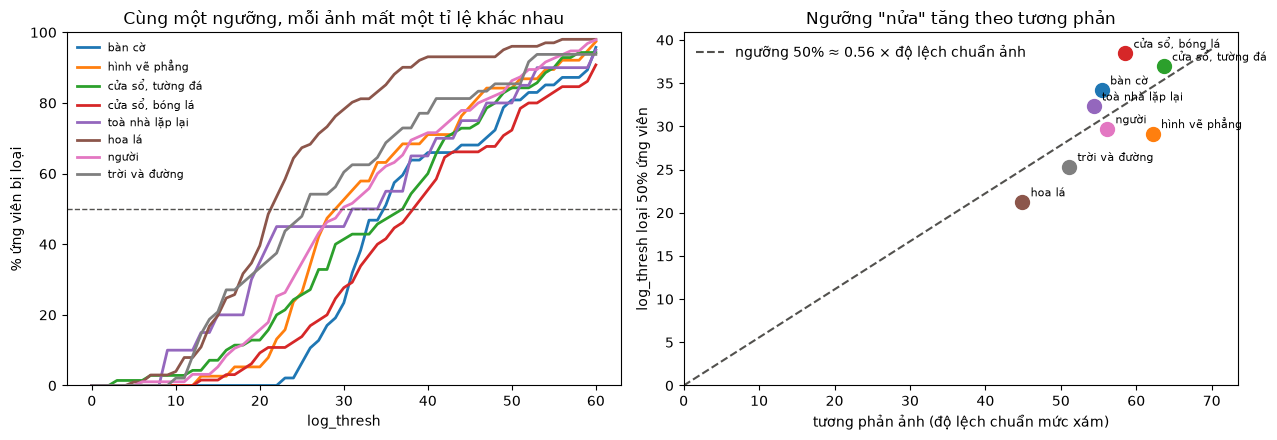

ảnh                    tương phản  ngưỡng 50%   % bị loại ở log_thresh=10
chess.jpg                    55.4        34.2                          0%
test2.jpg                    62.2        29.2                          0%
window.jpg                   63.6        37.0                          3%
window2.jpg                  58.5        38.5                          0%
test1.jpg                    54.3        32.3                         10%
flowers.jpg                  44.9        21.3                          4%
grey_astronauts.jpg          56.1        29.7                          1%
images2.jpg                  51.1        25.3                          2%


In [16]:
def log_at_points(img, points):
    """|LoG| chuẩn hoá tại từng điểm (row, col, σ): đúng giá trị mà log_thresh đem ra so."""
    cache = {s: h.log_normalized(img, s) for s in np.unique(points[:, 2])}
    return np.array([cache[s][int(y), int(x)] for y, x, s, _ in points])


LOG_THRESHOLDS = np.linspace(0, 60, 61)
kept_frac, contrast, t_half = {}, {}, {}
for name, grey in GREYS.items():
    a = cv.resize(grey, (SIZE_A, SIZE_A), interpolation=cv.INTER_AREA)
    pts = h.harris_laplace(a, SIGMAS_HL, log_thresh=0.0)
    vals = log_at_points(a, pts)
    # log_thresh là bộ lọc cuối cùng, nên đếm vals > t là đủ, không cần chạy lại cả thuật toán
    kept_frac[name] = np.array([(vals > t).mean() for t in LOG_THRESHOLDS])
    contrast[name] = a.std()
    t_half[name] = np.median(vals)                       # ngưỡng loại đúng 50% ứng viên
    # tự kiểm tra: phép đếm phải khớp với một lần gọi thật
    t_check = LOG_THRESHOLDS[20]
    assert len(h.harris_laplace(a, SIGMAS_HL, log_thresh=t_check)) == np.sum(vals > t_check), name

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
palette = plt.cm.tab10(np.arange(len(GREYS)))
for color, name in zip(palette, GREYS):
    ax1.plot(LOG_THRESHOLDS, 100 * (1 - kept_frac[name]), color=color, lw=2, label=REAL_IMAGES[name])
ax1.axhline(50, color='#52514e', ls='--', lw=1)
ax1.set_xlabel('log_thresh'); ax1.set_ylabel('% ứng viên bị loại'); ax1.set_ylim(0, 100)
ax1.set_title('Cùng một ngưỡng, mỗi ảnh mất một tỉ lệ khác nhau'); ax1.legend(frameon=False, fontsize=8)

xs = np.array([contrast[n] for n in GREYS]); ys = np.array([t_half[n] for n in GREYS])
for color, name, x, y in zip(palette, GREYS, xs, ys):
    ax2.plot(x, y, 'o', ms=10, color=color)
    ax2.annotate(REAL_IMAGES[name], (x, y), textcoords='offset points', xytext=(6, 4), fontsize=8)
slope = np.sum(xs * ys) / np.sum(xs ** 2)               # đường thẳng qua gốc, bình phương tối thiểu
ax2.plot([0, xs.max() * 1.1], [0, slope * xs.max() * 1.1], '--', color='#52514e', lw=1.5,
         label=f'ngưỡng 50% ≈ {slope:.2f} × độ lệch chuẩn ảnh')
ax2.set_xlim(0, None); ax2.set_ylim(0, None); ax2.legend(frameon=False, loc='upper left')
ax2.set_xlabel('tương phản ảnh (độ lệch chuẩn mức xám)'); ax2.set_ylabel('log_thresh loại 50% ứng viên')
ax2.set_title('Ngưỡng "nửa" tăng theo tương phản')
plt.tight_layout(); plt.show()

print(f'{"ảnh":22s}{"tương phản":>11s}{"ngưỡng 50%":>12s}{"% bị loại ở log_thresh=10":>28s}')
for name in GREYS:
    print(f'{name:22s}{contrast[name]:11.1f}{t_half[name]:12.1f}{100 * (1 - kept_frac[name][10]):27.0f}%')


## 9. Kết luận

> **Khai báo AI** — phần này do AI (Claude) viết từ số liệu chạy được ở trên. Prompt: *"bạn làm hộ tui đi nói chứ qua môn r bạn ơi nên tui nhờ bạn á bạn bị nhầm á cái này tài liệu của anh chị á"*

### 9.1 Bằng chứng khác biệt (mục 5, 8.2, 8.4)

| | Harris cổ điển | Harris-Laplace |
|---|---|---|
| Phóng 3×, TB 8 ảnh | **0.19** | **0.41** |
| Xoay, TB 8 ảnh và 7 góc | **0.97** | **0.90** |

- Phóng 3×: Harris-Laplace hơn trên 7/8 ảnh. Riêng bàn cờ thì gần hoà (0.36 với 0.34).
- Phóng 1.5×: Harris cổ điển lại hơn trên 7/8 ảnh, ví dụ hình vẽ phẳng 1.00 so với 0.87. Lý do nằm ở 9.2: 1.5× không trùng một số nguyên tầng của tháp ξ = 1.4.
- Xoay: Harris cổ điển nhỉnh hơn. Cả hai đều dùng R = det M − k (tr M)², nên đều không đổi khi xoay. Harris-Laplace thua chút có lẽ vì nó giữ thêm điểm ở σ lớn, mà điểm ở σ lớn thì định vị kém chính xác hơn trong khi ε = 3 px cố định. Đây là giả thuyết, chưa đo riêng.
- Mọi repeatability ở đây chỉ tính trên vùng cách mép B ít nhất 6 px. Đây là dải mà `harris_classic` không phát hiện điểm (xem 9.4), áp dụng như nhau cho cả hai detector.

**Đại lượng nào tính khác đi, ở bước nào, vì sao:**
- **Đại lượng:** σ dùng để tính R tại mỗi điểm. Harris cổ điển dùng một cặp (σ_I = 2, σ_D = 1.4) cho cả ảnh. Harris-Laplace cho mỗi điểm một σ riêng, là tầng mà |LoG| = σ²|Lxx + Lyy| đạt cực đại theo trục tỉ lệ.
- **Bước:** bước 2 của `harris_laplace`, so |LoG| ở tầng σ_n với hai tầng σ_{n−1}, σ_{n+1}.
- **Vì sao ra hiện tượng:** phóng ảnh k lần thì cấu trúc to ra k lần, nên đỉnh |LoG| dời sang σ lớn gấp k (mục 2, 3). Harris-Laplace đi theo đỉnh đó nên vẫn thấy góc. Harris cổ điển giữ cửa sổ σ_I = 2 cố định, nên góc to ra trông như một cạnh thẳng: một trị riêng của M lớn, một trị riêng nhỏ, R < 0, và điểm bị loại.

### 9.2 Quét ξ (mục 8.5)

- **Không có đường bão hoà kiểu "ξ càng nhỏ càng tốt".** Phóng 2×, repeatability TB chỉ dao động 0.60–0.77 khi ξ đi từ 1.1 tới 2.0. Trong khi đó thời gian chạy tăng **6.6 lần** (19 s lên 126 s), vì số tầng tăng từ 7 lên 40.
- **Điểm nổi bật là ξ = 2.0 cao nhất khi phóng 2×, và ξ = 1.6 thấp nhất.** Phép thử chéo 8.5b xác nhận:

| | ξ = 1.6 | ξ = 2.0 |
|---|---|---|
| phóng 1.6× | **0.812** (lệch 0 tầng) | 0.702 (lệch 0.32) |
| phóng 2.0× | 0.603 (lệch 0.47) | **0.772** (lệch 0 tầng) |

- **Cơ chế:** σ chỉ được chọn trong các tầng rời rạc σ_n = ξ^n σ0. Phóng k lần thì σ thật phải dời đi log k / log ξ tầng.
  - Nếu đó là số nguyên, điểm ở B rơi đúng vào tầng tương ứng của A, và hàng xóm theo trục tỉ lệ cũng y hệt. Cực đại |LoG| được giữ ở cả hai ảnh.
  - Nếu lệch nửa tầng, các tầng của B nằm giữa hai tầng của A. Đỉnh |LoG| bị lấy mẫu ở chỗ khác, nên một số điểm qua được phép so `>` ở A nhưng trượt ở B.
- **Kết luận:** muốn ổn định với **mọi** hệ số phóng thì phải giảm độ lệch tối đa (0.5 tầng × log ξ). Đó là lý do nên chọn ξ nhỏ (1.2–1.4) dù chậm hơn. ξ lớn chỉ "thắng" ở vài hệ số phóng may mắn trùng tầng.

### 9.3 Quét log_thresh (mục 8.6)

- Từ 0 tới khoảng 10, log_thresh gần như không loại gì (0–10%). Sau đó tỉ lệ bị loại tăng nhanh, mỗi ảnh mất 50% ở một ngưỡng khác nhau, **21 (hoa lá) tới 38 (cửa sổ, bóng lá)**.
- **Cơ chế:** |LoG| là phép tuyến tính theo cường độ, nên nhân tương phản với c thì |LoG| cũng nhân c. Một ngưỡng tuyệt đối vì vậy nghiêm khắc hơn với ảnh tương phản thấp: ảnh hoa lá (độ lệch chuẩn 45) mất một nửa số điểm sớm nhất. Ngưỡng "nửa" tăng cùng tương phản, nhưng không tỉ lệ chặt (≈ 0.47–0.66 × độ lệch chuẩn). Độ lệch chuẩn của cả ảnh chỉ là ước lượng thô cho tương phản *tại góc*.
- **Hệ quả thực tế:** log_thresh nên đặt tương đối, ví dụ theo max |LoG| hoặc theo độ lệch chuẩn ảnh, giống cách `thresh_rel` làm với R. Nếu không, cùng một tham số cho kết quả rất khác nhau giữa các ảnh.

### 9.4 Ghi chú về cài đặt

Bản trước của `harris_laplace` giữ cả điểm ở tầng σ đầu tiên, nơi chỉ có một tầng kề để so. Khi đó 46% điểm trên `window.jpg` nằm ở σ = 1.2, và repeatability khi phóng 3× bị thổi lên (TB 0.54). Sau khi sửa theo đúng đề (cần lớn hơn **cả hai** tầng kề, dấu `>` chặt), con số thật là **0.41**.

`harris_classic` bỏ các điểm cách mép ảnh dưới ceil(3σ_I) = 6 px. Lọc Gauss với tới khoảng 3σ, nên trong dải đó ảnh bị phản chiếu ở mép và sinh góc giả. Đo bằng cách cắt ô giữa ảnh rồi so với ảnh đầy đủ: điểm trong 6 px sát mép giả 28–64%, xa hơn chỉ khoảng 7%. `repeatability` vì thế cũng bỏ các điểm chiếu vào dải 6 px đó của B (tham số `border`, đặt 0 để tính như đề gốc). Nếu không bỏ, kiểm chứng xoay 30° tụt từ 0.964 xuống 0.896 chỉ do cách đo.
